# 09 - Caudal do rio: reanálise GloFAS

| | |
|---|---|
| **Tarefa do plano** | Série para o gatilho de alertas e para validação (apoia a S1-09) |
| **Variáveis (Parte I)** | #44 caudal do rio |
| **Fonte** | GloFAS histórico (Copernicus EMS) através da API do CEMS Early Warning Data Store |
| **Saída** | `data/raw/discharge/glofas/` |

**Antes de correr**

1. Entrar em <https://ewds.climate.copernicus.eu/> com a conta Copernicus/ECMWF,
   abrir o dataset *GloFAS historical* e aceitar a licença (uma vez).
2. Colocar o token pessoal da API no `.env` como `CDS_API_KEY`.

As chaves do pedido foram confirmadas com o servidor em outubro de 2026. Se o
servidor voltar a rejeitar o pedido, abrir o separador *Download* do dataset,
carregar em *Show API request* e alinhar as chaves no dicionário `request`.

Correr primeiro `00_setup_and_authentication` e `01_study_area_aoi`. Todos os
downloads podem ser retomados: os ficheiros que já existem são saltados, e cada
ficheiro fica registado em `data/metadata/download_manifest.csv`.

In [3]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import cdsapi
import pandas as pd
from datetime import date
from ete import config
from ete import grid as G

cfg = config.load_config()
ds = cfg["datasets"]["glofas"]
OUT_DIR = config.path(cfg, "glofas")
west, south, east, north = G.load_aoi(cfg, "aoi_climate").total_bounds
client = cdsapi.Client(url=ds["api_url"], key=os.environ["CDS_API_KEY"])

## 1. Download (um NetCDF por ano)

In [4]:
VARIABLE = "average_river_discharge_in_the_last_24_hours"
this_year = date.today().year

def fetch(year, product_type, months, out):
    request = {
        "system_version": [ds["system_version"]],
        "hydrological_model": [ds["hydrological_model"]],
        "product_type": [product_type],
        "timespan": ["time_mean"],
        "variable": [VARIABLE],
        "year": [str(year)],
        "month": months,
        "day": [f"{d:02d}" for d in range(1, 32)],
        "data_format": "netcdf",
        "download_format": "unarchived",
        "area": [float(north), float(west), float(south), float(east)],   # N, O, S, E
    }
    row = dict(dataset="glofas", source_id=f"{ds['dataset']} {ds['system_version']} {product_type}",
               period=str(year), bands="dis24", crs="EPSG:4326", resolution=0.05)
    try:
        client.retrieve(ds["dataset"], request, str(out))
        config.log_manifest(cfg, status="downloaded", file=out, n_images=len(months), **row)
    except Exception as err:
        config.log_manifest(cfg, status="failed", note=repr(err)[:300], **row)
        print(year, product_type, "FALHOU:", repr(err)[:300])

def months_available(year, product_type):
    # o servidor diz que meses existem para cada ano e tipo de produto
    valid = client.client.apply_constraints(ds["dataset"], {
        "system_version": [ds["system_version"]], "product_type": [product_type],
        "variable": [VARIABLE], "year": [str(year)]})
    return sorted(valid.get("month", []))

name = cfg["project"]["aoi_name"]
for year in range(ds["start_year"], this_year + 1):
    out = OUT_DIR / f"glofas_discharge_{name}_{year}.nc"
    # o ano corrente é atualizado em cada execução; ficheiros vazios (pedido interrompido) são refeitos
    if out.exists() and out.stat().st_size > 0 and year < this_year:
        continue
    consolidated = months_available(year, "consolidated")
    if consolidated:
        fetch(year, "consolidated", consolidated, out)
    # meses recentes ainda sem produto consolidado: produto intermédio, em ficheiro à parte
    recent = [m for m in months_available(year, "intermediate") if m not in consolidated] if year >= this_year - 1 else []
    if recent:
        fetch(year, "intermediate", recent, OUT_DIR / f"glofas_discharge_{name}_{year}_intermediate.nc")
sorted(p.name for p in OUT_DIR.glob("*.nc"))

2026-10-08 20:26:56,728 INFO [2024-02-01T00:00:00] Please note that accessing this dataset via CDS for time-critical operation is not advised or supported
2026-10-08 20:26:56,729 INFO [2024-02-01T00:00:00] Please note we suggest checking the list of known issues on the GloFAS wiki
[here](https://confluence.ecmwf.int/display/CEMS/GloFAS+-+Known+Issues)
before downloading the dataset.
2026-10-08 20:26:56,731 INFO [2026-07-30T00:00:00] Due to changes in the data structure of the cems-glofas-historical dataset, previous API requests may no longer work. Please refer to the updated API request and update your scripts accordingly. Please refer to [GloFAS historical: Changes to the EWDS API Request](https://confluence.ecmwf.int/pages/viewpage.action?pageId=699325478) for more information.
2026-10-08 20:26:56,732 INFO Request ID is ebef25ee-30a0-425e-8a58-e2a6b3a19086
2026-10-08 20:26:59,219 INFO status has been updated to successful


e992ca1be252214cbb7545a8817b3cb0.nc:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

2026-10-08 20:27:10,346 INFO [2024-02-01T00:00:00] Please note that accessing this dataset via CDS for time-critical operation is not advised or supported
2026-10-08 20:27:10,346 INFO [2024-02-01T00:00:00] Please note we suggest checking the list of known issues on the GloFAS wiki
[here](https://confluence.ecmwf.int/display/CEMS/GloFAS+-+Known+Issues)
before downloading the dataset.
2026-10-08 20:27:10,347 INFO [2026-07-30T00:00:00] Due to changes in the data structure of the cems-glofas-historical dataset, previous API requests may no longer work. Please refer to the updated API request and update your scripts accordingly. Please refer to [GloFAS historical: Changes to the EWDS API Request](https://confluence.ecmwf.int/pages/viewpage.action?pageId=699325478) for more information.
2026-10-08 20:27:10,348 INFO Request ID is 235c8643-f422-4e00-b9e3-20caeaf9e293
2026-10-08 20:27:11,063 INFO status has been updated to accepted
2026-10-08 20:27:26,219 INFO status has been updated to running

398e4377f6a0511f344a61de25b0dd73.nc:   0%|          | 0.00/1.15M [00:00<?, ?B/s]

2026-10-08 20:31:45,180 INFO [2024-02-01T00:00:00] Please note that accessing this dataset via CDS for time-critical operation is not advised or supported
2026-10-08 20:31:45,181 INFO [2024-02-01T00:00:00] Please note we suggest checking the list of known issues on the GloFAS wiki
[here](https://confluence.ecmwf.int/display/CEMS/GloFAS+-+Known+Issues)
before downloading the dataset.
2026-10-08 20:31:45,181 INFO [2026-07-30T00:00:00] Due to changes in the data structure of the cems-glofas-historical dataset, previous API requests may no longer work. Please refer to the updated API request and update your scripts accordingly. Please refer to [GloFAS historical: Changes to the EWDS API Request](https://confluence.ecmwf.int/pages/viewpage.action?pageId=699325478) for more information.
2026-10-08 20:31:45,182 INFO Request ID is 62cb70f1-0fda-4389-a765-4c8cd7c991ea
2026-10-08 20:31:45,494 INFO status has been updated to accepted
2026-10-08 20:32:09,557 INFO status has been updated to running

2d94ffd1e2b390abec63af8601b45bad.nc:   0%|          | 0.00/984k [00:00<?, ?B/s]

... (29 outputs left out)

171d80be8b78354031e9ed3d6306f6bf.nc:   0%|          | 0.00/819k [00:00<?, ?B/s]

2026-10-09 06:44:44,078 INFO [2024-02-01T00:00:00] Please note that accessing this dataset via CDS for time-critical operation is not advised or supported
2026-10-09 06:44:44,079 INFO [2024-02-01T00:00:00] Please note we suggest checking the list of known issues on the GloFAS wiki
[here](https://confluence.ecmwf.int/display/CEMS/GloFAS+-+Known+Issues)
before downloading the dataset.
2026-10-09 06:44:44,079 INFO [2026-07-30T00:00:00] Due to changes in the data structure of the cems-glofas-historical dataset, previous API requests may no longer work. Please refer to the updated API request and update your scripts accordingly. Please refer to [GloFAS historical: Changes to the EWDS API Request](https://confluence.ecmwf.int/pages/viewpage.action?pageId=699325478) for more information.
2026-10-09 06:44:44,080 INFO Request ID is 9dd49a29-a969-43f7-9833-96053820d907
2026-10-09 06:44:44,348 INFO status has been updated to accepted
2026-10-09 06:45:07,056 INFO status has been updated to running

e3d9f7af691d677528a7b803ed12fac7.nc:   0%|          | 0.00/299k [00:00<?, ?B/s]

['glofas_discharge_marracuene_2006.nc',
 'glofas_discharge_marracuene_2007.nc',
 'glofas_discharge_marracuene_2008.nc',
 'glofas_discharge_marracuene_2009.nc',
 'glofas_discharge_marracuene_2010.nc',
 'glofas_discharge_marracuene_2011.nc',
 'glofas_discharge_marracuene_2012.nc',
 'glofas_discharge_marracuene_2013.nc',
 'glofas_discharge_marracuene_2014.nc',
 'glofas_discharge_marracuene_2015.nc',
 'glofas_discharge_marracuene_2016.nc',
 'glofas_discharge_marracuene_2017.nc',
 'glofas_discharge_marracuene_2018.nc',
 'glofas_discharge_marracuene_2019.nc',
 'glofas_discharge_marracuene_2020.nc',
 'glofas_discharge_marracuene_2021.nc',
 'glofas_discharge_marracuene_2022.nc',
 'glofas_discharge_marracuene_2023.nc',
 'glofas_discharge_marracuene_2024.nc',
 'glofas_discharge_marracuene_2025.nc',
 'glofas_discharge_marracuene_2026.nc',
 'glofas_discharge_marracuene_2026_intermediate.nc']

O produto *consolidated* tem um atraso de alguns meses em relação ao tempo real.
Os meses mais recentes vêm do produto *intermediate* e ficam num ficheiro à parte
(`..._intermediate.nc`), porque são provisórios e mais tarde são substituídos.

## 2. Série de caudal em Marracuene

A série é retirada da célula com o maior caudal médio dentro do retângulo
envolvente do distrito, ou seja, o curso principal do Incomáti. Confirmar a
localização no mapa antes de usar a série como gatilho de alertas.

avg_dis {'valid_time': 7581, 'latitude': 55, 'longitude': 78} m**3 s**-1
célula do curso principal: lat -25.725, lon 32.675


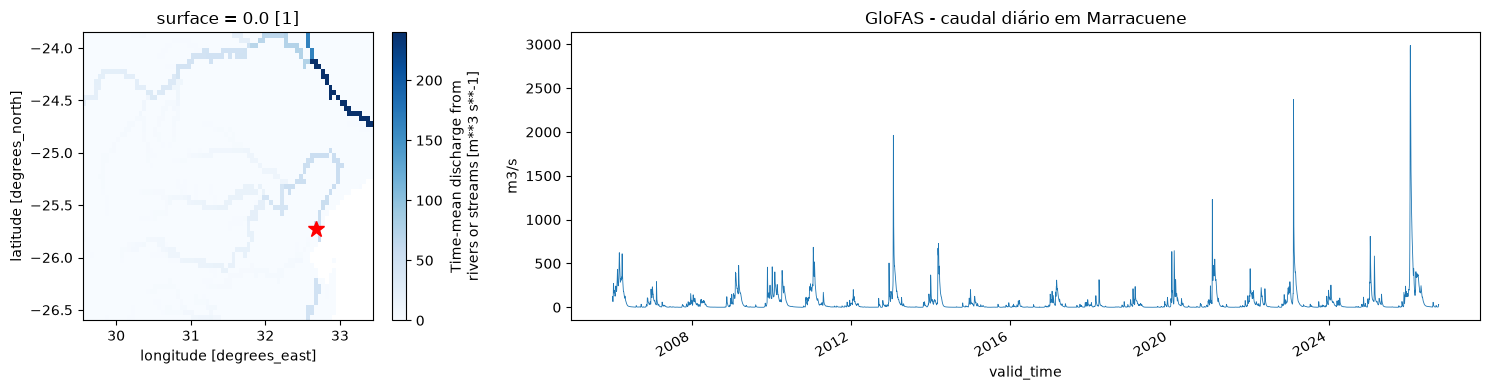

In [5]:
import xarray as xr
import matplotlib.pyplot as plt

files = sorted(OUT_DIR.glob("glofas_discharge_*.nc"))
parts = [xr.open_dataset(f) for f in files]
var = [v for v in parts[0].data_vars if parts[0][v].ndim >= 3][0]
time_dim = [d for d in parts[0][var].dims if "time" in d][0]
dis = xr.concat([p[var] for p in parts], dim=time_dim).squeeze(drop=True).sortby(time_dim)
print(var, dict(dis.sizes), dis.attrs.get("units"))

lat, lon = [d for d in dis.dims if "lat" in d][0], [d for d in dis.dims if "lon" in d][0]
w, s, e, n = G.load_aoi(cfg, "district").total_bounds
local = dis.where((dis[lat] >= s) & (dis[lat] <= n) & (dis[lon] >= w) & (dis[lon] <= e), drop=True)
mean = local.mean(time_dim)
cell = mean.where(mean == mean.max(), drop=True)
cell_lat, cell_lon = float(cell[lat][0]), float(cell[lon][0])
print(f"célula do curso principal: lat {cell_lat:.3f}, lon {cell_lon:.3f}")

q = dis.sel({lat: cell_lat, lon: cell_lon}).to_series().rename("discharge_m3s")
csv = config.path(cfg, "interim", "discharge", "glofas_daily_marracuene.csv")
q.to_csv(csv, index_label="date")

fig, axes = plt.subplots(1, 2, figsize=(15, 4), width_ratios=[1, 2.5])
dis.mean(time_dim).plot(ax=axes[0], cmap="Blues"); axes[0].plot(cell_lon, cell_lat, "r*", markersize=12)
q.plot(ax=axes[1], linewidth=0.6, ylabel="m3/s", title="GloFAS - caudal diário em Marracuene")
plt.tight_layout()